# **Retail Sales Performance & Logistics Pipeline**
### End-to-End Analytics Pipeline using SQL (SQLite) & Python (Pandas, Seaborn)

**Author:** Chhaya Singh  
**Tech Stack:** SQL (DDL, DML, CTEs, Window Functions), Python (Pandas, Matplotlib, Seaborn), SQLite3  
**Dataset:** US Superstore Sales Dataset (9,800 Transaction Records)

# **Project Executive Summary**

Retail companies process millions of customer transactions across diverse territories, fulfillment methods, and product categories. Optimizing operational profitability requires rigorous tracking of gross revenue contribution, annual growth trends, and supply chain fulfillment speeds.

This project delivers an end-to-end data pipeline that:
1. **Cleanses & Normalizes Data:** Handles date format standardization and populates an in-memory SQL database.
2. **Leverages Advanced SQL:** Employs aggregate queries, subqueries, Common Table Expressions (CTEs), and window functions (`RANK() OVER PARTITION BY`) to isolate revenue drivers.

**Step 1: Data Ingestion, Date Standardization & Relational Table Setup**



**Objective:** Load raw transactional records, clean column headers, format date dimensions to prevent arithmetic type errors, engineer delivery duration features, and persist records into a local SQLite database (`orders` table).

In [8]:
import sqlite3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set clean styling for visualizations
sns.set_theme(style="whitegrid")

# 1. Load the uploaded train.csv dataset
df = pd.read_csv("/content/superstore data set .csv")

# 2. Standardize column names (lowercase and replace spaces/hyphens with underscores)
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

# 3. Robust Datetime Conversion (explicit DD/MM/YYYY format)
df["order_date"] = pd.to_datetime(
    df["order_date"], format="%d/%m/%Y", errors="coerce"
)
df["ship_date"] = pd.to_datetime(
    df["ship_date"], format="%d/%m/%Y", errors="coerce"
)

# 4. Feature Engineering: Shipping duration in days and order year
df["shipping_days"] = (df["ship_date"] - df["order_date"]).dt.days
df["order_year"] = df["order_date"].dt.year

# 5. Create SQLite database connection
db_conn = sqlite3.connect("superstore_sales.db")

# 6. Ingest cleaned DataFrame into SQL table 'orders'
df.to_sql("orders", db_conn, if_exists="replace", index=False)

print("--- Step 1 Successfully Executed ---")
print(f"Total rows stored in SQL table: {len(df):,}")
print(
    f"Average shipping days across dataset: {df['shipping_days'].mean():.2f} days"
)

--- Step 1 Successfully Executed ---
Total rows stored in SQL table: 9,800
Average shipping days across dataset: 3.96 days


**Step 2: Product Sub-Category Performance & Revenue Contribution**

**Objective:** Execute SQL aggregations to evaluate total sales volume, order counts, and Average Order Value (AOV) across product sub-categories, identifying primary revenue drivers.

Top 10 Sub-Categories by Total Sales:


,category,sub_category,total_orders,total_sales,avg_order_value
0,Technology,Phones,876,327782.45,374.18
1,Furniture,Chairs,607,322822.73,531.83
2,Office Supplies,Storage,832,219343.39,263.63
3,Furniture,Tables,314,202810.63,645.89
4,Office Supplies,Binders,1492,200028.79,134.07
5,Technology,Machines,115,189238.63,1645.55
6,Technology,Accessories,756,164186.70,217.18
7,Technology,Copiers,66,146248.09,2215.88
8,Furniture,Bookcases,226,113813.20,503.60
9,Office Supplies,Appliances,459,104618.40,227.93


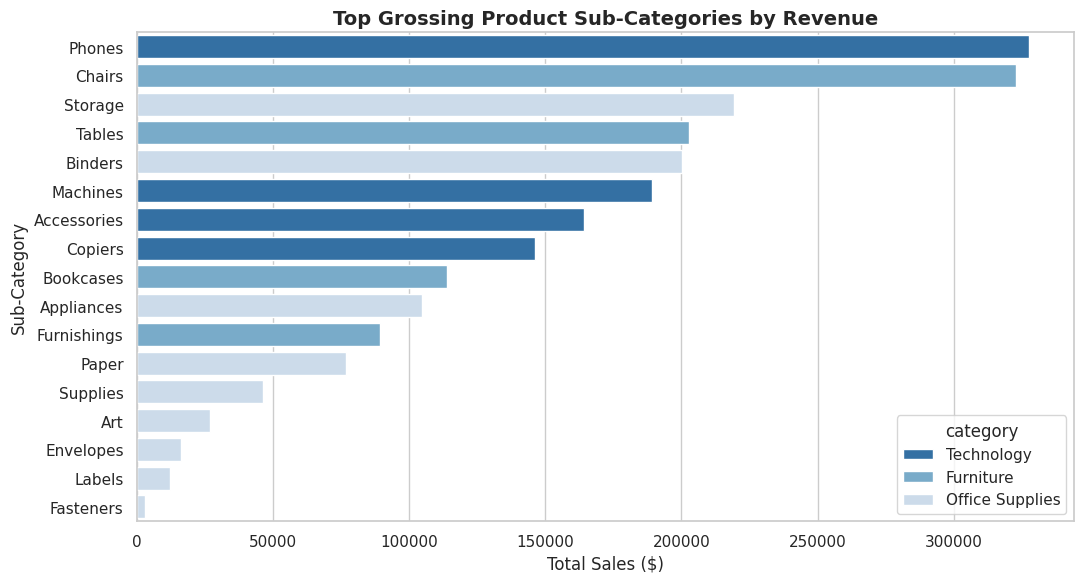

In [4]:
# SQL Query: Aggregate sales, order counts, and average order value per sub-category
sql_subcat = """
SELECT
    category,
    sub_category,
    COUNT(order_id) AS total_orders,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(AVG(sales), 2) AS avg_order_value
FROM orders
GROUP BY category, sub_category
ORDER BY total_sales DESC;
"""

df_subcat = pd.read_sql_query(sql_subcat, db_conn)
print("Top 10 Sub-Categories by Total Sales:")
display(df_subcat.head(10))

# Visualization: Horizontal Bar Chart of Sales by Sub-Category
plt.figure(figsize=(11, 6))
sns.barplot(
    data=df_subcat,
    x="total_sales",
    y="sub_category",
    hue="category",
    dodge=False,
    palette="Blues_r",
)
plt.title(
    "Top Grossing Product Sub-Categories by Revenue",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Total Sales ($)")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.savefig("subcategory_sales_performance.png", dpi=300)
plt.show()

**Step 3: Geographic Performance & Regional Market Share**

**Objective:** Determine regional sales distribution and compute each territory's percentage contribution to gross company revenue using SQL subqueries and comparative bar charts.

Regional Performance Summary:


,region,total_orders,total_sales,sales_share_pct
0,West,1587,710219.68,31.40
1,East,1369,669518.73,29.60
2,Central,1156,492646.91,21.78
3,South,810,389151.46,17.21


/tmp/ipykernel_4411/2587122048.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


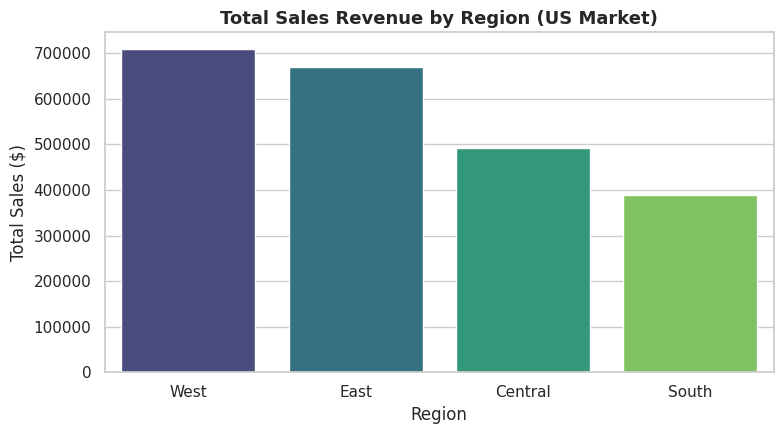

In [5]:
# SQL Query: Regional sales contribution and share of gross sales
sql_region = """
SELECT
    region,
    COUNT(DISTINCT order_id) AS total_orders,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND((SUM(sales) / (SELECT SUM(sales) FROM orders)) * 100, 2) AS sales_share_pct
FROM orders
GROUP BY region
ORDER BY total_sales DESC;
"""

df_region = pd.read_sql_query(sql_region, db_conn)
print("Regional Performance Summary:")
display(df_region)

# Visualization: Regional Sales Performance
plt.figure(figsize=(8, 4.5))
sns.barplot(
    data=df_region, x="region", y="total_sales", palette="viridis"
)
plt.title(
    "Total Sales Revenue by Region (US Market)", fontsize=13, fontweight="bold"
)
plt.xlabel("Region")
plt.ylabel("Total Sales ($)")
plt.tight_layout()
plt.savefig("regional_sales_breakdown.png", dpi=300)
plt.show()

**Step 4: Supply Chain Turnaround & Shipping Fulfillment Analysis**

**Objective:** Analyze logistics delivery efficiency by measuring average transit days across different shipping tiers and customer segments to evaluate operational bottlenecks.

--- Shipping Logistics & Turnaround Summary ---


,ship_mode,segment,total_orders,avg_delivery_days,total_sales
0,First Class,Consumer,755,2.2,158104.95
1,First Class,Corporate,468,2.2,102580.05
2,First Class,Home Office,278,2.1,84887.26
3,Same Day,Consumer,312,0.0,57452.27
4,Same Day,Corporate,114,0.1,45121.32
5,Same Day,Home Office,112,0.1,22645.44
6,Second Class,Consumer,1003,3.2,230125.54
7,Second Class,Corporate,589,3.3,139045.29
8,Second Class,Home Office,310,3.3,80743.35
9,Standard Class,Consumer,3031,5.0,702377.78


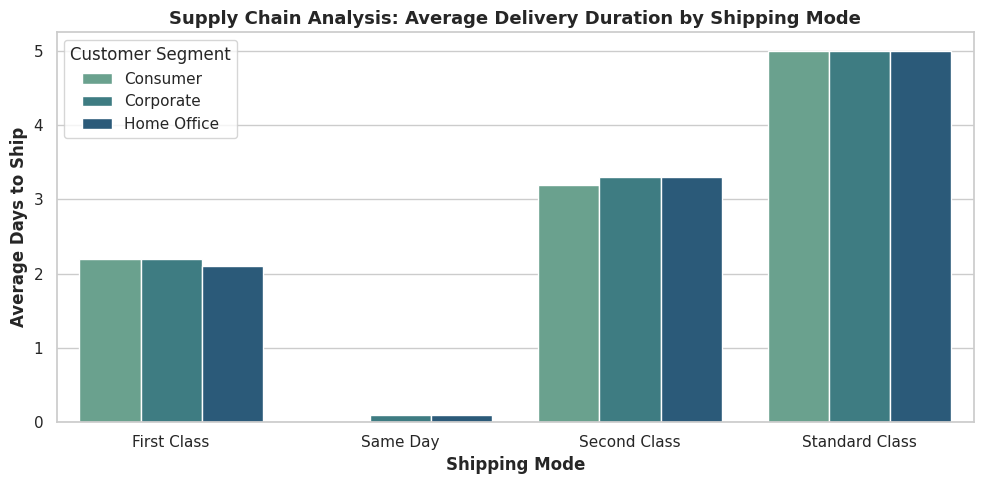

Chart successfully generated and saved as 'shipping_turnaround_analysis.png'!


In [9]:
# SQL Query: Shipping turnaround efficiency and revenue contribution by segment
sql_shipping = """
SELECT
    ship_mode,
    segment,
    COUNT(order_id) AS total_orders,
    ROUND(AVG(shipping_days), 1) AS avg_delivery_days,
    ROUND(SUM(sales), 2) AS total_sales
FROM orders
GROUP BY ship_mode, segment
ORDER BY ship_mode, total_sales DESC;
"""

# Execute SQL query via Pandas
df_shipping = pd.read_sql_query(sql_shipping, db_conn)
print("--- Shipping Logistics & Turnaround Summary ---")
display(df_shipping)

# Visualization: Average Delivery Days by Shipping Mode & Segment
plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_shipping,
    x="ship_mode",
    y="avg_delivery_days",
    hue="segment",
    palette="crest"
)
plt.title("Supply Chain Analysis: Average Delivery Duration by Shipping Mode", fontsize=13, fontweight="bold")
plt.xlabel("Shipping Mode", fontweight="bold")
plt.ylabel("Average Days to Ship", fontweight="bold")
plt.legend(title="Customer Segment")
plt.tight_layout()

# Save chart image for GitHub portfolio README
plt.savefig("shipping_turnaround_analysis.png", dpi=300)
plt.show()
print("Chart successfully generated and saved as 'shipping_turnaround_analysis.png'!")

**Step 5: Executive KPI Synthesis & Business Performance Summary**

**Objective:** Formulate an enterprise-level summary query to aggregate high-level operational and financial KPIs—including total distinct orders, active customer accounts, overall unit volume, gross revenue, Average Order Value (AOV), and enterprise shipping turnaround—providing a comprehensive executive snapshot.

In [10]:
# SQL Query: Extract executive-level business KPIs
sql_kpi = """
SELECT
    COUNT(DISTINCT order_id) AS total_orders,
    COUNT(DISTINCT customer_id) AS total_customers,
    COUNT(product_id) AS total_items_sold,
    ROUND(SUM(sales), 2) AS total_revenue,
    ROUND(AVG(sales), 2) AS avg_order_value,
    ROUND(AVG(shipping_days), 1) AS overall_avg_shipping_days
FROM orders;
"""

df_kpi = pd.read_sql_query(sql_kpi, db_conn)

print("=" * 55)
print("       SUPERSTORE RETAIL PERFORMANCE METRICS       ")
print("=" * 55)
print(f"Total Unique Orders Processed : {df_kpi['total_orders'][0]:,}")
print(f"Total Customer Base           : {df_kpi['total_customers'][0]:,}")
print(f"Total Line Items Sold         : {df_kpi['total_items_sold'][0]:,}")
print(f"Gross Revenue Generated       : ${df_kpi['total_revenue'][0]:,.2f}")
print(f"Average Order Value (AOV)     : ${df_kpi['avg_order_value'][0]:,.2f}")
print(f"Average Turnaround Time       : {df_kpi['overall_avg_shipping_days'][0]} Days")
print("=" * 55)

       SUPERSTORE RETAIL PERFORMANCE METRICS       
Total Unique Orders Processed : 4,922
Total Customer Base           : 793
Total Line Items Sold         : 9,800
Gross Revenue Generated       : $2,261,536.78
Average Order Value (AOV)     : $230.77
Average Turnaround Time       : 4.0 Days


**Step 6: Advanced SQL — Category Ranking within Regions (CTEs & Window Functions)**

**Objective:** Utilize Common Table Expressions (CTEs) combined with the `RANK() OVER (PARTITION BY region ORDER BY total_revenue DESC)` window function to rank category dominance within each geographic territory.

In [11]:
# SQL Query: Using Common Table Expressions (CTE) and Window Functions (RANK)
sql_window_rank = """
WITH regional_category_sales AS (
    SELECT
        region,
        category,
        ROUND(SUM(sales), 2) AS total_revenue,
        COUNT(order_id) AS total_orders
    FROM orders
    GROUP BY region, category
)
SELECT
    region,
    category,
    total_revenue,
    total_orders,
    RANK() OVER (PARTITION BY region ORDER BY total_revenue DESC) AS category_rank
FROM regional_category_sales
ORDER BY region, category_rank;
"""

df_rank = pd.read_sql_query(sql_window_rank, db_conn)
print("--- Regional Category Ranking (Window Function Output) ---")
display(df_rank)

--- Regional Category Ranking (Window Function Output) ---


,region,category,total_revenue,total_orders,category_rank
0,Central,Technology,168739.21,408,1
1,Central,Office Supplies,163590.24,1399,2
2,Central,Furniture,160317.46,470,3
3,East,Technology,263116.53,527,1
4,East,Furniture,206461.39,591,2
5,East,Office Supplies,199940.81,1667,3
6,South,Technology,148195.21,289,1
7,South,Office Supplies,124424.77,983,2
8,South,Furniture,116531.48,326,3
9,West,Technology,247404.93,589,1


**Step 7: Multi-Year Revenue Trend & Strategic Growth Analysis**

**Objective:** Extract annual revenue trajectory (2015–2018) via SQL aggregations and plot a stylized line chart to track company sales expansion and transaction velocity over time.

--- Annual Sales Performance ---


,order_year,total_orders,annual_sales
0,2015,947,479856.21
1,2016,1019,459436.01
2,2017,1295,600192.55
3,2018,1661,722052.02


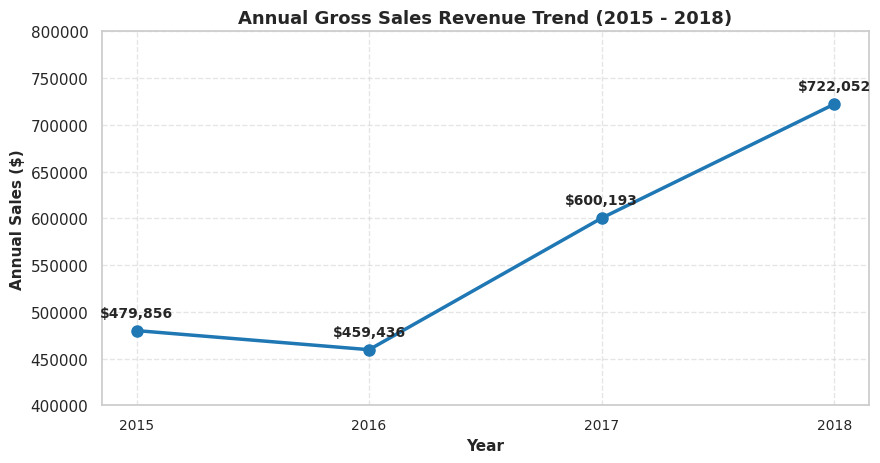

Line chart generated and saved successfully as 'annual_sales_trend.png'!


In [12]:
# SQL Query: Yearly total sales and unique orders trend
sql_yearly_trend = """
SELECT
    order_year,
    COUNT(DISTINCT order_id) AS total_orders,
    ROUND(SUM(sales), 2) AS annual_sales
FROM orders
GROUP BY order_year
ORDER BY order_year;
"""

# Fetch data into Pandas DataFrame
df_trend = pd.read_sql_query(sql_yearly_trend, db_conn)
print("--- Annual Sales Performance ---")
display(df_trend)

# Visualization: Professional Line Chart with Data Labels
plt.figure(figsize=(9, 4.8))
plt.plot(
    df_trend["order_year"],
    df_trend["annual_sales"],
    marker="o",
    color="#1f77b4",
    linewidth=2.5,
    markersize=8,
    label="Gross Revenue",
)

# Add exact revenue numbers on top of each data point
for i, row in df_trend.iterrows():
    plt.annotate(
        f"${row['annual_sales']:,.0f}",
        (row["order_year"], row["annual_sales"]),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontweight="bold",
        fontsize=10,
    )

plt.title(
    "Annual Gross Sales Revenue Trend (2015 - 2018)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Year", fontweight="bold", fontsize=11)
plt.ylabel("Annual Sales ($)", fontweight="bold", fontsize=11)
plt.xticks(df_trend["order_year"], fontsize=10)
plt.ylim(400000, 800000)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

# Save chart image for portfolio documentation
plt.savefig("annual_sales_trend.png", dpi=300)
plt.show()
print("Line chart generated and saved successfully as 'annual_sales_trend.png'!")